**1.Importing Libraries and Dataset**

In [32]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import lightgbm as lgb

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error as mse
from lightgbm import LGBMRegressor

import warnings
warnings.filterwarnings('ignore')

In [33]:
df = pd.read_csv('Data/medical_cost.csv')

In [34]:
df.head()

,Id,age,sex,bmi,children,smoker,region,charges
0,1,19,female,27.900,0,yes,southwest,16884.92400
1,2,18,male,33.770,1,no,southeast,1725.55230
2,3,28,male,33.000,3,no,southeast,4449.46200
3,4,33,male,22.705,0,no,northwest,21984.47061
4,5,32,male,28.880,0,no,northwest,3866.85520


In [35]:
df.shape

(1338, 8)

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        1338 non-null   int64  
 1   age       1338 non-null   int64  
 2   sex       1338 non-null   object 
 3   bmi       1338 non-null   float64
 4   children  1338 non-null   int64  
 5   smoker    1338 non-null   object 
 6   region    1338 non-null   object 
 7   charges   1338 non-null   float64
dtypes: float64(2), int64(3), object(3)
memory usage: 83.8+ KB


In [37]:
df.describe()

,Id,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,669.500000,39.207025,30.663397,1.094918,13270.422265
std,386.391641,14.049960,6.098187,1.205493,12110.011237
min,1.000000,18.000000,15.960000,0.000000,1121.873900
25%,335.250000,27.000000,26.296250,0.000000,4740.287150
50%,669.500000,39.000000,30.400000,1.000000,9382.033000
75%,1003.750000,51.000000,34.693750,2.000000,16639.912515
max,1338.000000,64.000000,53.130000,5.000000,63770.428010


**2. Exploratory Data Analysis (EDA)**

In [38]:
categorical_cols = ['sex', 'children', 'smoker', 'region']

for col in categorical_cols:
    grouped_data = df[[col, 'charges']].groupby(col).mean()
    print(f"Mean charges by {col}:")
    print(grouped_data)
    print()

Mean charges by sex:
             charges
sex                 
female  12569.578844
male    13956.751178

Mean charges by children:
               charges
children              
0         12365.975602
1         12731.171832
2         15073.563734
3         15355.318367
4         13850.656311
5          8786.035247

Mean charges by smoker:
             charges
smoker              
no       8434.268298
yes     32050.231832

Mean charges by region:
                charges
region                 
northeast  13406.384516
northwest  12417.575374
southeast  14735.411438
southwest  12346.937377



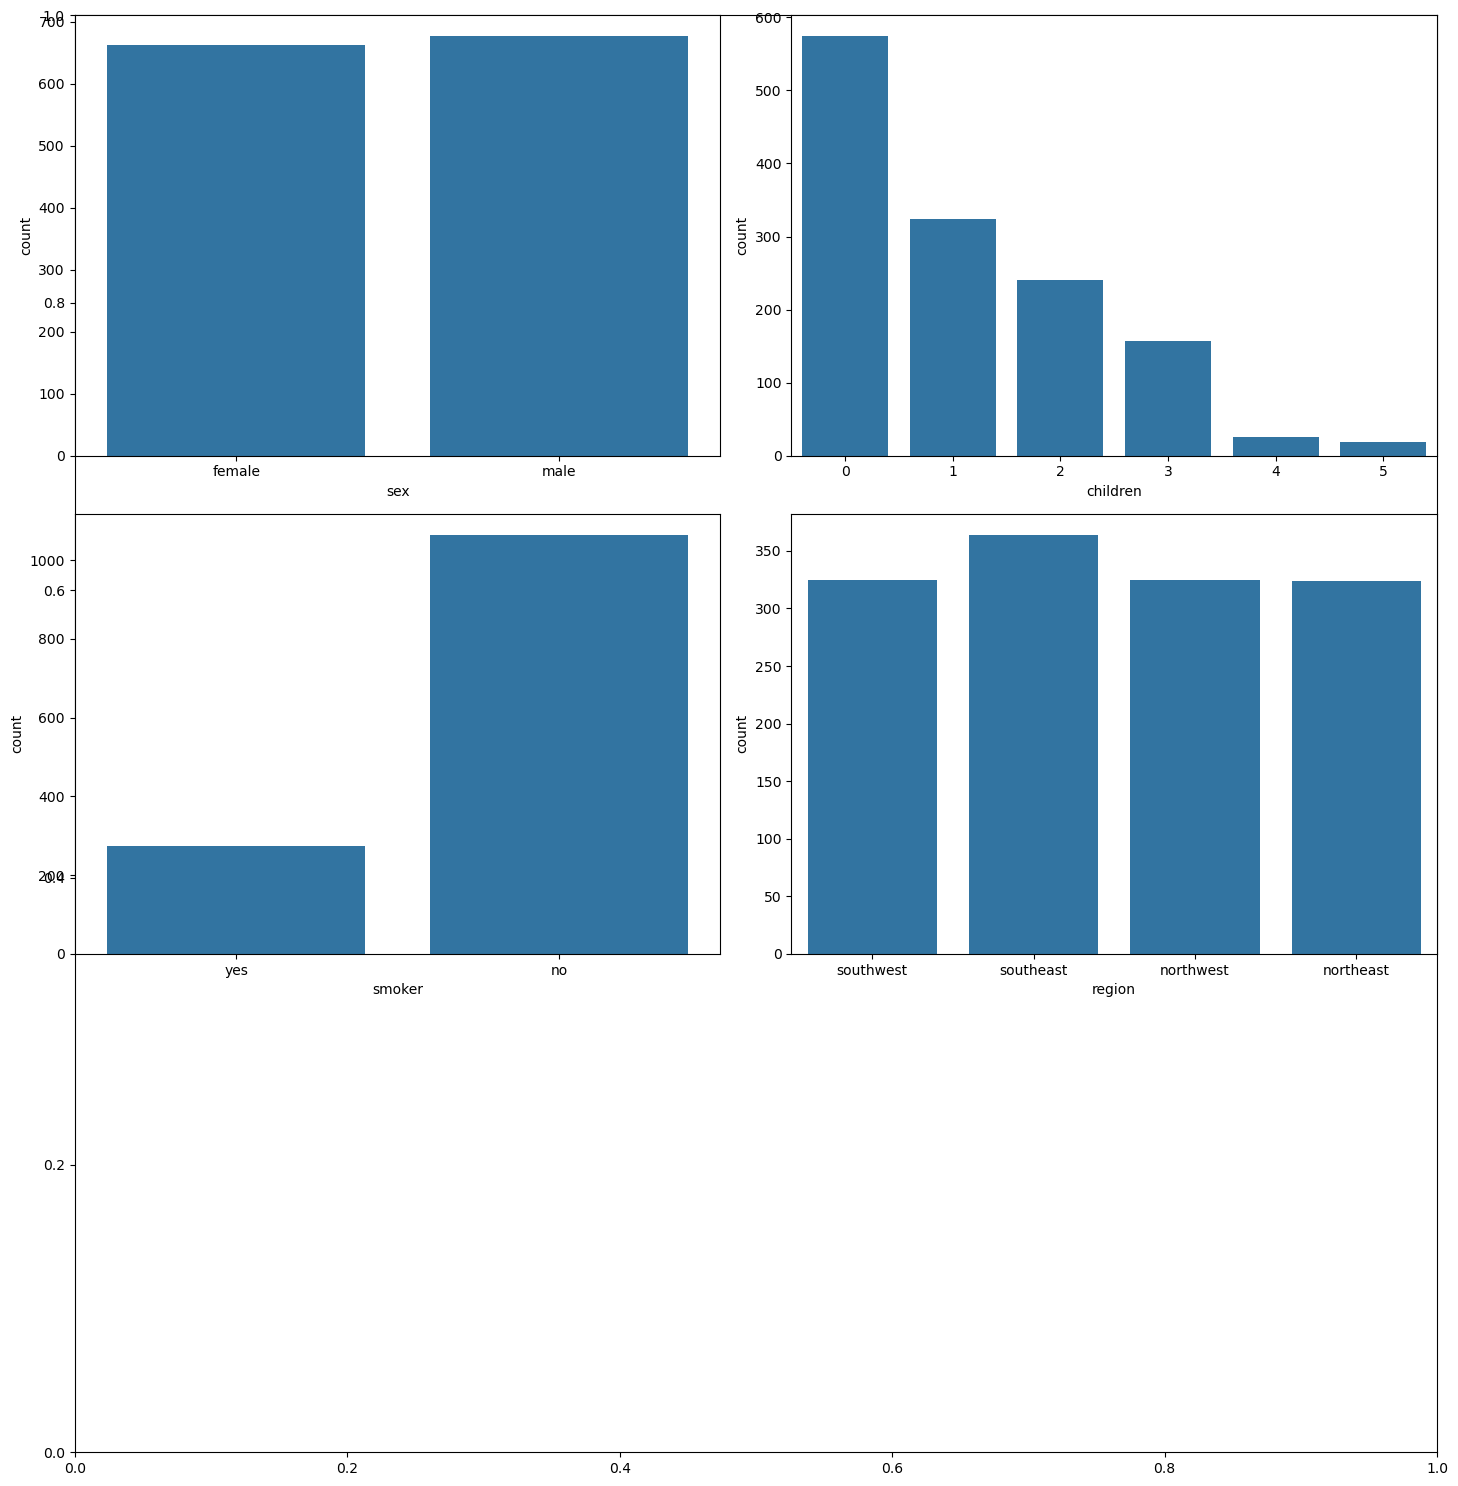

In [39]:
plt.subplots(figsize=(15, 15))
for i, col in enumerate(categorical_cols):
    plt.subplot(3,2,i+1)
    sb.countplot(data = df, x=col)
plt.tight_layout()
plt.show()

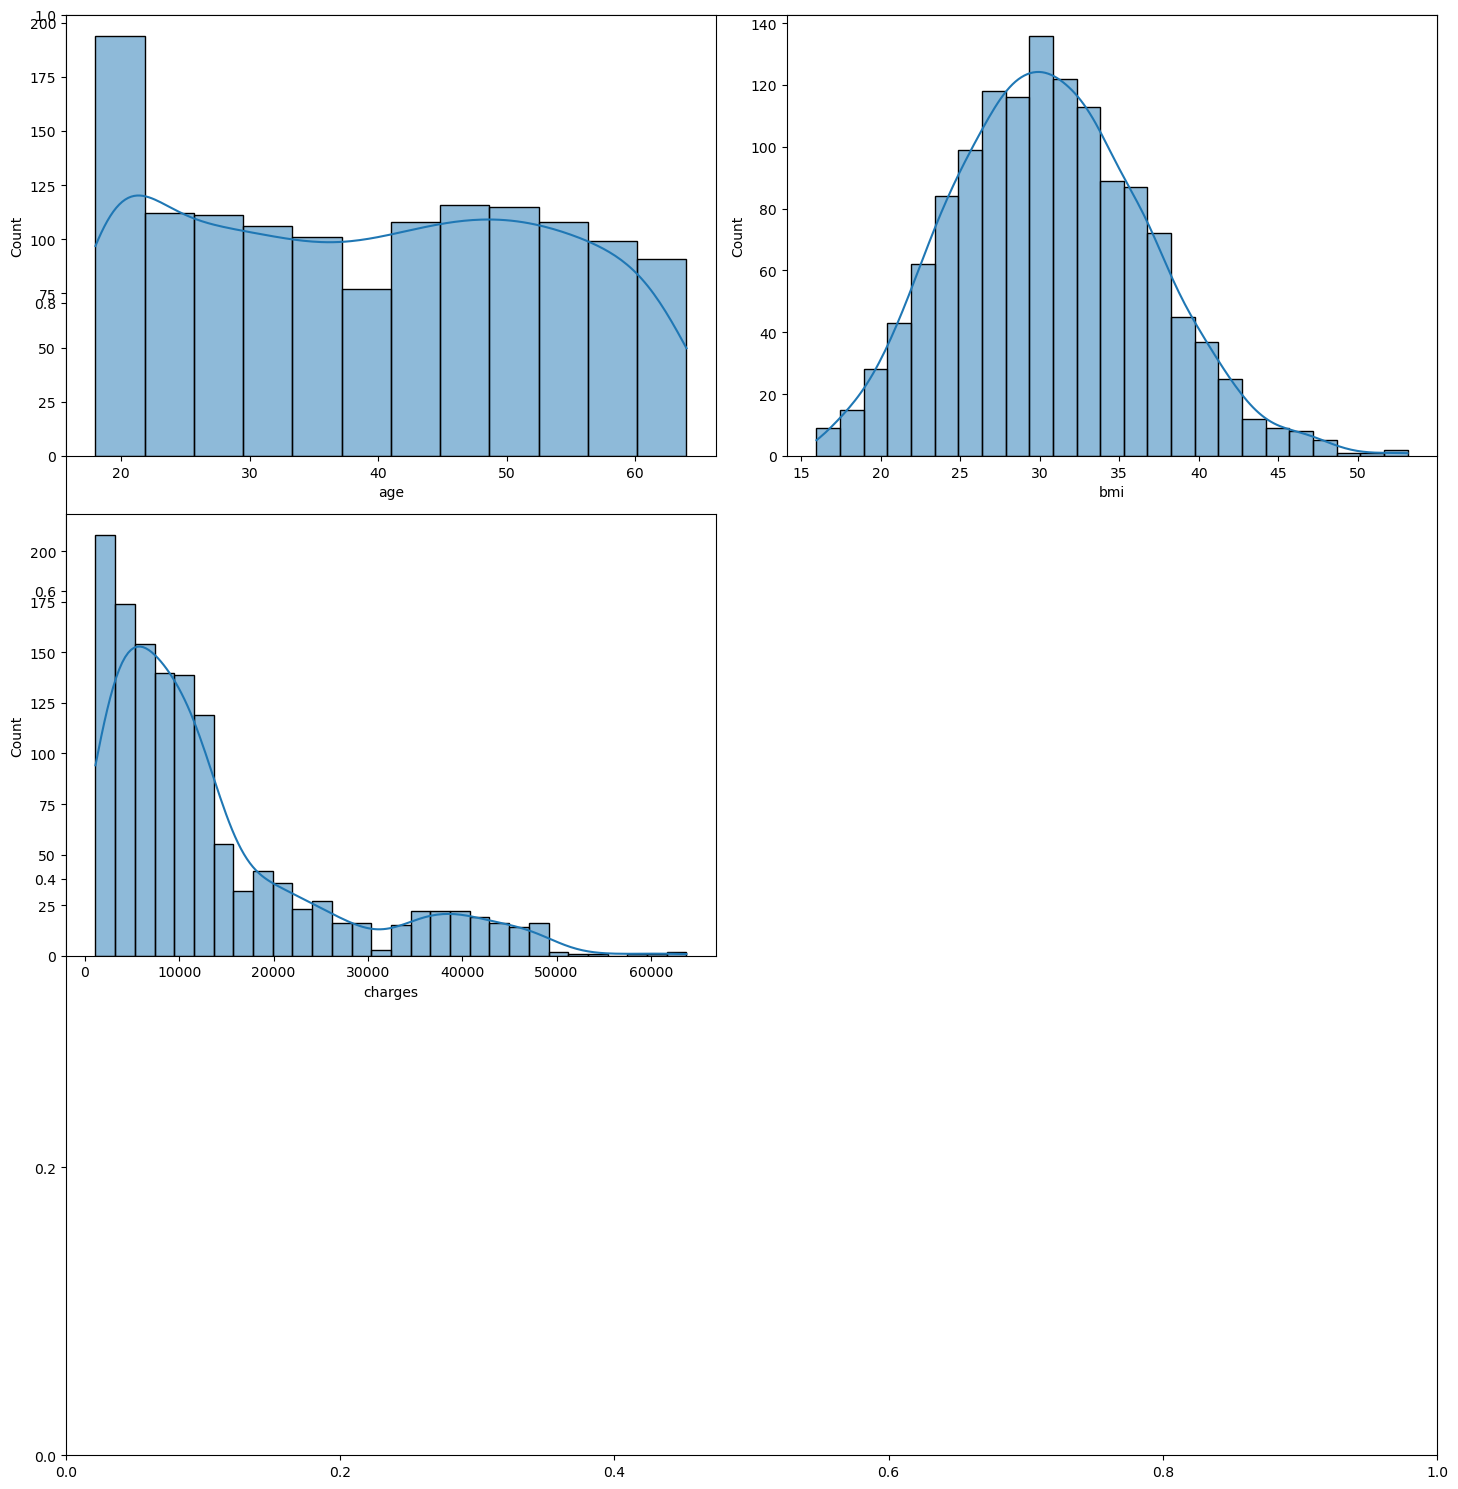

In [40]:
numeric_cols = ['age', 'bmi', 'charges']
plt.subplots(figsize = (15,15))
for i , col in enumerate(numeric_cols):
    plt.subplot(3,2,i+1)
    sb.histplot(df[col], kde=True)
plt.tight_layout()
plt.show()

**4.Data Preprocessing**

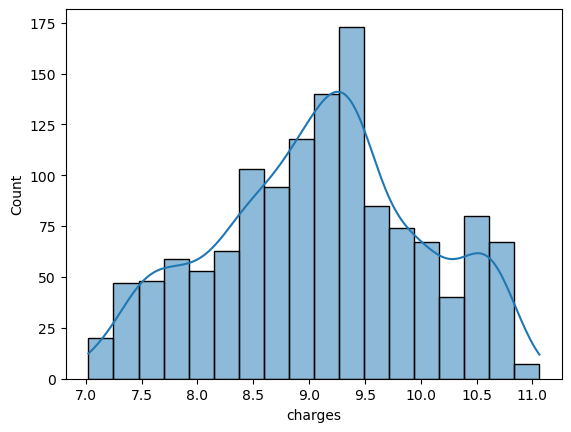

In [41]:
df['charges'] = np.log1p(df['charges'])
sb.histplot(df['charges'], kde = True)
plt.show()

In [42]:
# map() – Converts categories to 0/1
df['sex'] = df['sex'].map({'male':0, 'female':1})
df['smoker'] = df['smoker'].map({'no':0, 'yes':1})
df.head()

,Id,age,sex,bmi,children,smoker,region,charges
0,1,19,1,27.900,0,1,southwest,9.734236
1,2,18,0,33.770,1,0,southeast,7.453882
2,3,28,0,33.000,3,0,southeast,8.400763
3,4,33,0,22.705,0,0,northwest,9.998137
4,5,32,0,28.880,0,0,northwest,8.260455


In [43]:
df = pd.concat([df, pd.get_dummies(df['region']).astype('int')],axis=1)
df.drop(['Id', 'region'],inplace=True, axis=1)
df.head()

,age,sex,bmi,children,smoker,charges,northeast,northwest,southeast,southwest
0,19,1,27.900,0,1,9.734236,0,0,0,1
1,18,0,33.770,1,0,7.453882,0,0,1,0
2,28,0,33.000,3,0,8.400763,0,0,1,0
3,33,0,22.705,0,0,9.998137,0,1,0,0
4,32,0,28.880,0,0,8.260455,0,1,0,0


**5.Splitting and Scaling Data**

In [46]:
features = df.drop('charges', axis=1)
target = df['charges']
X_train, X_val, Y_train, Y_val = train_test_split(features, target, test_size=0.25, random_state=2023)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

**5.Dataset Preparation for LightGBM**

In [47]:
train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_val, label=Y_val, reference=train_data)

**6. Regression Model Using LightGBM**

In [50]:
params = {
    'objective':'regression',
    'metric':'rmse',
    'boosting_type':'gbdt',
    'num_leaves':31,
    'learning_rate':0.05,
    'feature_fraction':0.9
}
num_round = 100
bst = lgb.train(params, train_data, num_round, valid_sets=[test_data], early_stopping_rounds=10)

[LightGBM] [Warning] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001090 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 328
[LightGBM] [Info] Number of data points in the train set: 1003, number of used features: 9
[LightGBM] [Info] Start training from score 9.081718
[1]	valid_0's rmse: 0.880618
Training until validation scores don't improve for 10 rounds
[2]	valid_0's rmse: 0.844723
[3]	valid_0's rmse: 0.810578
[4]	valid_0's rmse: 0.799112
[5]	valid_0's rmse: 0.78874
[6]	valid_0's rmse: 0.758207
[7]	valid_0's rmse: 0.729812
[8]	valid_0's rmse: 0.703424
[9]	valid_0's rmse: 0.678731
[10]	valid_0's rmse: 0.655224
[11]	valid_0's rmse: 0.633106
[12]	valid_0's rmse: 0.613178
[13]	valid_0's rmse: 0.594686
[14]	valid_0's rmse: 0.577297
[15]	valid_0's rmse: 0.561479
[16]	valid_0's rmse: 0.546608
[17]	valid_0's rmse: 0.532843
[18]	valid_0's rmse: 0.520173
[19

**7.Prediction and Evaluation**

In [53]:
model = LGBMRegressor(metric='rmse')
model.fit(X_train,Y_train)
y_train = model.predict(X_train)
y_val = model.predict(X_val)

print("Training RMSE: ", np.sqrt(mse(Y_train, y_train)))
print("Validation RMSE: ", np.sqrt(mse(Y_val, y_val)))

Training RMSE:  0.2331835443343122
Validation RMSE:  0.40587871797893876
